# Phase H - Tang bien do mieng cho C4 (hau xu ly, khong train lai)

Mo hinh C4 (`StudentAudio2Landmark`, `phaseB/C4_motion_emo_e20_lr3e4/phaseB_best.pth`) du doan chuyen dong **M**
(da tru TB clip) cua ham duoi (diem 3-13) va mieng (48-67). Tren test, mieng mo **qua it**: ti le bien do do mo moi
(std du doan / std that) chi ~0.62, tuong quan ~0.56, M-LMD ~0.028.

**Y tuong.** Chieu M len **dung co so PCA mieng-ham ma demo dang dung** (`phaseB/mouth_pca.npz`, 12 thanh phan, hoc tu
12 speaker train dau, giong `A.fit_mouth_pca` trong notebook demo). Voi moi thanh phan k:
`g_k = std(that_k) / std(du doan_k)` tren **VAL**, kep trong [1, 3]. Nhan he so PCA cua M voi gain, phan ngoai PCA
giu nguyen.

| Cell | Noi dung |
| :--- | :--- |
| 0 | Mount Drive, tu tim `Data_student` (`DRIVE_ROOT_OVERRIDE` neu tim sai) |
| 1 | Cau hinh |
| 2 | Lay repo, nap C4, co so PCA mieng-ham cua demo, do lech TB theo nhan |
| 3 | Nap VAL / TEST, du doan M cua C4 (dieu kien cam xuc nhu Phase B: one-hot x muc/3) |
| 4 | Nap cua so landmark that cua speaker train (PCA cho FD, bo phan loai cam xuc cho Emo-Acc) |
| 5 | Ham tinh chi so (giong Phase B + Phase E) + bootstrap theo clip |
| 6 | **Tim cau hinh tren VAL**: gain tung thanh phan `g_k^alpha` / 1 he so chung, nhan **truoc** hoac **sau** lam muot 110 ms |
| 7 | Kiem tra buoc **kep PCA +-2 sigma** cua demo co cat mat phan khuech dai khong (neu co -> doi gioi han kep) |
| 8 | **Ap len TEST** (4 speaker chua thay): bang truoc / sau + khoang tin cay 95% (bootstrap theo clip) |
| 9 | Luu ket qua vao `student_a2l/phaseH/` + hinh do mo moi theo thoi gian |

**Thu tu ap gain** (theo chuoi hau xu ly cua demo: kep PCA -> lam muot 110 ms):
* `before_smooth`: gain -> kep PCA -> lam muot.  * `after_smooth`: kep PCA -> lam muot -> gain.

Gain va lam muot deu tuyen tinh nen neu khong co buoc kep (tanh) o giua thi 2 thu tu cho **ket qua y het**; khac
nhau chi do buoc kep. Vi vay buoc tim tren VAL danh gia moi ung vien tren **chuoi demo** (kep PCA + lam muot 110 ms).

**Quy tac chon (chi dung VAL):** trong cac cau hinh co M-LMD mieng <= 1.05 x "demo cu" (khong gain) **va** ti le rung
(du doan / that) <= 1.2, chon cau hinh co bien do **gan 1 nhat** (bang nhau thi chon tuong quan cao hon).
Test chi dung de bao cao.

**Ket qua** (`MyDrive/DAT301m/Data_student/student_a2l/phaseH/`): `mouth_gain.json`, `phaseH_val_search.csv`,
`phaseH_test_results.csv`, `phaseH_test_table.md`, `phaseH_mouth_open.png`. Notebook **khong ghi** vao thu muc nao khac.

Dung ket qua: o Cell 1 cua notebook demo (`3_phaseC_demo_render`) hoac benchmark (`5_phaseE_benchmark`) dat
`MOUTH_GAIN_PATH = '/content/drive/MyDrive/DAT301m/Data_student/student_a2l/phaseH/mouth_gain.json'`.
Hai notebook doc `order` trong file de ap gain dung thu tu. De `None` = hanh vi cu y nguyen.

Thoi gian tren T4: ~10-15 phut (du doan ~3 phut, nap train ~3 phut, bootstrap ~2 phut).

## Cell 0 - Mount Drive va tu tim thu muc du lieu (dung duoc voi tai khoan Google khac co shortcut)

In [1]:
# Cell 0 - Mount Drive + TU TIM thu muc du lieu (chay duoc ca khi dung tai khoan Google khac, co shortcut)
import os, sys, glob
from pathlib import Path

DRIVE_ROOT_OVERRIDE = ''      # neu tu tim sai: dien tay, vd '/content/drive/MyDrive/DAT301m/Data_student'
MEAD_ROOT_OVERRIDE  = ''      # vd '/content/drive/.shortcut-targets-by-id/1GwXP.../MEAD'

if 'google.colab' in sys.modules and not os.path.isdir('/content/drive/MyDrive'):
    from google.colab import drive
    drive.mount('/content/drive')


def _is_data_root(p):
    # thu muc Data_student that: co du lieu MEAD da xu ly hoac thu muc ket qua student_a2l
    return os.path.isdir(os.path.join(p, 'Data_emotion_mead_task_b')) or os.path.isdir(os.path.join(p, 'student_a2l'))


def _is_mead(p):
    return os.path.isdir(p) and any(os.path.isfile(os.path.join(p, d, 'audio.tar')) for d in ('M003', 'M005', 'W033', 'M032'))


def _score(p):
    # 3: co du lieu MEAD da xu ly (split.json) | 2: co thu muc MEAD da xu ly | 1: chi co thu muc ket qua student_a2l
    if os.path.isfile(os.path.join(p, 'Data_emotion_mead_task_b', 'phaseB_ready', 'split.json')):
        return 3
    if os.path.isdir(os.path.join(p, 'Data_emotion_mead_task_b')):
        return 2
    return 1 if os.path.isdir(os.path.join(p, 'student_a2l')) else 0


def find_drive_root():
    if DRIVE_ROOT_OVERRIDE:
        return Path(DRIVE_ROOT_OVERRIDE)
    base = '/content/drive'
    cands = [base + '/MyDrive/DAT301m/Data_student']
    # shortcut nam o MyDrive (ten bat ky), shortcut tro toi DAT301m hoac Data_student, thu muc chia se (Shared drives)
    for pat in ('/MyDrive/*/Data_student', '/MyDrive/*/*/Data_student', '/MyDrive/Data_student',
                '/.shortcut-targets-by-id/*/DAT301m/Data_student', '/.shortcut-targets-by-id/*/Data_student',
                '/.shortcut-targets-by-id/*/*/Data_student', '/.shortcut-targets-by-id/*/*/*/Data_student',
                '/Shareddrives/*/DAT301m/Data_student', '/Shareddrives/*/Data_student', '/MyDrive/*'):
        cands += sorted(glob.glob(base + pat))
    seen, scored = set(), []
    for c in cands:
        r = os.path.realpath(c)
        if r in seen or not os.path.isdir(c):
            continue
        seen.add(r)
        sc = _score(c)
        if sc:
            scored.append((sc, c))
    for sc, c in sorted(scored, key=lambda x: -x[0]):
        print('  ung vien: %-90s diem %d' % (c, sc))
    best = max(scored, key=lambda x: x[0]) if scored else None     # max giu thu tu uu tien khi bang diem
    return Path(best[1]) if best else None


def find_mead_root():
    if MEAD_ROOT_OVERRIDE:
        return Path(MEAD_ROOT_OVERRIDE)
    base = '/content/drive'
    for pat in ('/.shortcut-targets-by-id/1GwXP-KpWOxOenOxITTsURJZQ_1pkd4-j/MEAD', '/.shortcut-targets-by-id/*/MEAD',
                '/MyDrive/MEAD', '/MyDrive/*/MEAD', '/MyDrive/*/*/MEAD', '/Shareddrives/*/MEAD', '/Shareddrives/*/*/MEAD'):
        for c in sorted(glob.glob(base + pat)):
            if _is_mead(c):
                return Path(c)
    return None


def _writable(p):
    try:
        t = Path(p) / '.write_test'
        t.write_text('ok'); t.unlink()
        return True
    except Exception:
        return False


if 'google.colab' in sys.modules:
    DRIVE_FOUND, MEAD_FOUND = find_drive_root(), find_mead_root()
    assert DRIVE_FOUND is not None, ('Khong tim thay thu muc Data_student. Kiem tra shortcut (chuot phai thu muc DAT301m '
                                     'duoc chia se > Organize > Add shortcut > My Drive) hoac dien DRIVE_ROOT_OVERRIDE.')
    print('Data_student :', DRIVE_FOUND, '| ghi duoc:', _writable(DRIVE_FOUND))
    if _score(str(DRIVE_FOUND)) < 3:
        print('!!! Thu muc nay KHONG co Data_emotion_mead_task_b/phaseB_ready/split.json -> chua thay shortcut toi thu muc '
              'du lieu that. Them shortcut vao My Drive hoac dien DRIVE_ROOT_OVERRIDE.')
    print('MEAD goc     :', MEAD_FOUND if MEAD_FOUND else 'KHONG THAY (chi can cho cac cell doc audio MEAD goc)')
    if not _writable(DRIVE_FOUND):
        print('!!! Tai khoan nay chi co quyen XEM thu muc chia se -> khong luu duoc ket qua. '
              'Nho chu thu muc cap quyen "Nguoi chinh sua" (Editor) cho tai khoan nay.')

Mounted at /content/drive
  ung vien: /content/drive/MyDrive/DAT301m/Data_student                                                diem 3
Data_student : /content/drive/MyDrive/DAT301m/Data_student | ghi duoc: True
MEAD goc     : /content/drive/.shortcut-targets-by-id/1GwXP-KpWOxOenOxITTsURJZQ_1pkd4-j/MEAD


## Cell 1 - Cau hinh

In [2]:
import os, sys, json, time, subprocess, csv, gc
from pathlib import Path
import numpy as np
import torch

IN_COLAB = 'google.colab' in sys.modules
REPO_URL = 'https://github.com/hien087585/EXPRESSIVE-2D-CHARACTER-ANIMATION.git'
REPO_DIR = Path('/content/MakeItTalk')
DRIVE    = Path('/content/drive/MyDrive/DAT301m/Data_student')
DRIVE    = globals().get('DRIVE_FOUND') or DRIVE          # Cell 0 tu tim (tai khoan khac / shortcut)
CACHE    = Path('/content/phaseH_cache')                  # o dia Colab: du doan C4 (khoi chay lai neu chay lai cell)
_T = os.environ.get('PHASEH_TEST_ROOT')                   # chi dung khi chay thu ngoai Colab (doc Drive, ghi vao _T)
if _T:
    REPO_DIR = Path(os.environ.get('PHASEH_REPO', str(Path(_T) / 'repo')))
    DRIVE    = Path(os.environ.get('PHASEH_DRIVE', str(Path(_T) / 'drive')))
    CACHE    = Path(_T) / 'phaseH_cache'
READY    = DRIVE / 'Data_emotion_mead_task_b' / 'phaseB_ready'
PHASEB   = DRIVE / 'student_a2l' / 'phaseB'
CKPT     = PHASEB / 'C4_motion_emo_e20_lr3e4' / 'phaseB_best.pth'
OFF_PATH = PHASEB / 'label_offsets_train.npz'
PCA_PATH = PHASEB / 'mouth_pca.npz'                       # co so PCA mieng-ham cua demo Phase C (chi doc)
OUT      = Path(_T) / 'phaseH' if _T else DRIVE / 'student_a2l' / 'phaseH'    # noi DUY NHAT notebook ghi ket qua

ALPHAS      = [0.0, 0.25, 0.5, 0.75, 1.0]     # gain = g_k ** alpha
GAIN_RANGE  = (1.0, 3.0)                      # kep g_k
SCALARS     = np.round(np.arange(1.05, 2.501, 0.05), 2)   # phuong an 1 he so chung cho ca mieng-ham
ORDERS      = ['before_smooth', 'after_smooth']   # nhan gain truoc (gain -> kep -> muot) / sau (kep -> muot -> gain) lam muot
ORDER_VN    = {'before_smooth': 'truoc lam muot', 'after_smooth': 'sau lam muot'}
MLMD_TOL    = 0.05                            # M-LMD mieng duoc phep te hon "demo cu" toi da 5% (tren VAL)
RUNG_MAX    = 1.2                             # ti le rung (gia toc TB du doan / that) toi da (tren VAL)
TARGET_AMP  = 0.85                            # muc tieu bien do (chi de bao cao)
DEMO_MC     = dict(prior_clamp=2.0, keep_residual=0.25, smooth_ms=110)   # = PROFILE['mouth_ctrl'] cua demo
CLAMP_CANDS = [2.0, 2.5, 3.0, 3.5, 4.0]       # gioi han kep moi (x sigma du lieu that) neu kep cu cat mat gain
KEEP_MIN    = 0.90                            # buoc kep phai giu >= 90% phan bien do tang them
N_BOOT      = 1000                            # so lan bootstrap theo clip (khoang tin cay 95%)
RUN_EMO_ACC = True                            # train 2 bo phan loai cam xuc nhu Phase E (~1-2 phut tren T4)
EMO_WIN, EMO_HOP, EMO_DS = 100, 50, 2         # giong Phase E
N_PLOT      = 2                               # so clip test ve do mo moi
SEED        = 0
LEAD, W     = 8, 18                           # do lech audio -> mieng (mel-frame), cua so mo hinh (giong Phase B)

MAX_CLIPS   = int(os.environ.get('PHASEH_MAX_CLIPS', 0))    # >0: chi N clip dau moi tap (chi de chay thu)
N_TRAIN_SPK = int(os.environ.get('PHASEH_TRAIN_SPK', 0))    # >0: chi N speaker train (chi de chay thu)
if _T:
    N_BOOT = int(os.environ.get('PHASEH_N_BOOT', 50))

EMO_NAMES = ['neutral', 'angry', 'disgusted', 'fear', 'happy', 'sad', 'surprised', 'contempt']
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device', DEVICE, '| ket qua ->', OUT)
if DEVICE.type != 'cuda':
    print('[canh bao] Khong co GPU. Tren Colab: Runtime > Change runtime type > T4 GPU.')

device cuda | ket qua -> /content/drive/MyDrive/DAT301m/Data_student/student_a2l/phaseH


## Cell 2 - Repo, mo hinh C4, co so PCA mieng-ham cua demo

PCA: nap `phaseB/mouth_pca.npz` (file demo da luu). Neu chua co, tinh lai **y het** demo
(`fit_mouth_pca` chep nguyen tu `avatar_lib.py`: 12 speaker train dau, `lm_res`, tru TB tung clip, k = 12, seed 0)
va luu vao `phaseH/mouth_pca_rebuilt.npz` (khong ghi vao `phaseB/`).

In [3]:
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    if not (REPO_DIR / 'src' / 'models' / 'model_audio2landmark.py').exists():
        subprocess.run(['git', 'clone', '--depth', '1', REPO_URL, str(REPO_DIR)], check=True)
if str(REPO_DIR) not in sys.path:
    sys.path.insert(0, str(REPO_DIR))
from src.models.model_audio2landmark import StudentAudio2Landmark  # noqa: E402

MEAN_STD_PATH = REPO_DIR / 'src' / 'dataset' / 'utils' / 'MEAN_STD_AUTOVC_RETRAIN_MEL_AU.txt'
for p in (READY / 'split.json', CKPT, OFF_PATH, MEAN_STD_PATH):
    assert p.exists(), 'Thieu file: %s' % p
OUT.mkdir(parents=True, exist_ok=True); CACHE.mkdir(parents=True, exist_ok=True)
SPLIT = json.loads((READY / 'split.json').read_text())
ms = np.loadtxt(MEAN_STD_PATH, dtype=np.float64).reshape(2, 80)
MEL_MEAN, MEL_STD = ms[0].astype(np.float32), np.maximum(ms[1], 1e-5).astype(np.float32)

meta = torch.load(str(CKPT), map_location='cpu', weights_only=False)
assert meta.get('mode') == 'motion', 'Checkpoint khong phai che do motion: %s' % CKPT
MOTION_PTS = list(meta.get('motion_pts'))
MODEL = StudentAudio2Landmark.from_checkpoint(str(CKPT), map_location='cpu').to(DEVICE).eval()
MASK = np.zeros((68, 2), np.float32); MASK[MOTION_PTS] = 1.0; MASK = MASK.reshape(136)
zo = np.load(OFF_PATH)
OFF = {(int(e), int(l)): v.astype(np.float32) for e, l, v in zip(zo['emo'], zo['lvl'], zo['off'])}
del meta


def fit_mouth_pca(npz_paths, motion_pts, k=10, max_frames=300000, seed=0):
    # chep nguyen tu avatar_lib.py (notebook demo Phase C) de tai tao dung co so PCA cua demo
    idx = np.array([[2 * p, 2 * p + 1] for p in motion_pts]).ravel()
    rows, rng = [], np.random.default_rng(seed)
    per = max(1, max_frames // max(1, len(npz_paths)))
    for f in npz_paths:
        z = np.load(f)
        R, off = z['lm_res'], z['offsets']
        X = []
        for i in range(len(off) - 1):
            c = R[off[i]:off[i + 1]][:, idx].astype(np.float32)
            X.append(c - c.mean(0, keepdims=True))
        X = np.concatenate(X)
        rows.append(X[rng.choice(len(X), min(per, len(X)), replace=False)])
    X = np.concatenate(rows)
    mu = X.mean(0)
    U, S, Vt = np.linalg.svd(X - mu, full_matrices=False)
    var = S ** 2 / (len(X) - 1)
    return dict(mean=mu.astype(np.float32), comps=Vt[:k].astype(np.float32), sigma=np.sqrt(var[:k]).astype(np.float32),
                idx=idx, evr=(var[:k] / var.sum()).astype(np.float32), motion_pts=np.array(motion_pts))


if PCA_PATH.exists():
    MOUTH_PCA = dict(np.load(PCA_PATH)); PCA_SRC = str(PCA_PATH)
else:
    t0 = time.time()
    MOUTH_PCA = fit_mouth_pca([READY / (s + '.npz') for s in SPLIT['train'][:12]], MOTION_PTS, k=12)
    np.savez(OUT / 'mouth_pca_rebuilt.npz', **MOUTH_PCA)
    PCA_SRC = 'tinh lai nhu demo (12 speaker train dau) -> %s' % (OUT / 'mouth_pca_rebuilt.npz')
    print('Hoc PCA mieng-ham: %.0f s' % (time.time() - t0))
assert [int(p) for p in MOUTH_PCA['motion_pts']] == MOTION_PTS, 'PCA va C4 khac tap diem chuyen dong'
PIDX = MOUTH_PCA['idx'].astype(np.int64)
PMU, PV, PSIG = (MOUTH_PCA[k].astype(np.float32) for k in ('mean', 'comps', 'sigma'))
K = len(PSIG)
print('C4: %s | %.2fM tham so | emotion_dim %d' % (CKPT.parent.name, MODEL.num_parameters() / 1e6, MODEL.emotion_dim))
print('PCA mieng-ham: %d thanh phan, %.1f%% bien thien | nguon: %s' % (K, 100 * MOUTH_PCA['evr'].sum(), PCA_SRC))
print('  sigma (train):', np.round(PSIG, 4))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
C4: C4_motion_emo_e20_lr3e4 | 3.29M tham so | emotion_dim 7
PCA mieng-ham: 12 thanh phan, 99.6% bien thien | nguon: /content/drive/MyDrive/DAT301m/Data_student/student_a2l/phaseB/mouth_pca.npz
  sigma (train): [0.1894 0.0823 0.0542 0.0436 0.0369 0.0244 0.0193 0.0146 0.0143 0.0114
 0.0107 0.0086]


## Cell 3 - Nap VAL / TEST va du doan chuyen dong M cua C4

Giong Phase E: `mel[lead:]` cua clip ghep voi `lm_res_raw[:-lead]` (landmark **goc** = ground truth), cua so 18 khung
buoc 4, trung binh cac cua so chong nhau. Dieu kien cam xuc giong luc danh gia Phase B: one-hot cam xuc x `muc / 3`
(neutral = 0). Ket qua cuoi = do lech TB theo nhan + M (chi diem 3-13, 48-67).

In [4]:
def emo_vec(e, l):
    v = np.zeros(7, np.float32)
    if e > 0:
        v[e - 1] = l / 3.0
    return v


def load_eval(speakers, name):
    mel_l, raw_l, clips, refs, pos = [], [], [], {}, 0
    for sp in speakers:
        z = np.load(READY / (sp + '.npz'))
        mel, raw, off = z['mel'], z['lm_res_raw'], z['offsets']
        refs[sp] = z['ref'].astype(np.float32)
        for i in range(len(off) - 1):
            if MAX_CLIPS and len(clips) >= MAX_CLIPS:
                break
            a, b = int(off[i]), int(off[i + 1]); n = (b - a) - LEAD
            if n < W:
                continue
            mel_l.append(((mel[a:b].astype(np.float32) - MEL_MEAN) / MEL_STD).astype(np.float16))   # mel DAY DU cua clip
            raw_l.append(raw[a:b - LEAD].astype(np.float32))
            clips.append(dict(pos=pos, n=n, sp=sp, emo=int(z['emo'][i]), lvl=int(z['lvl'][i]), name=str(z['names'][i]),
                              mel_i=len(mel_l) - 1))
            pos += n
    D = dict(clips=clips, refs=refs, mel=mel_l, raw=np.concatenate(raw_l))
    print('%-5s %d speaker | %d clip | %.2f gio' % (name, len(speakers), len(clips), pos / 62.5 / 3600))
    return D


@torch.no_grad()
def predict_clip(m, mel, ev, stride=4):
    # mel day du cua clip (n + LEAD, 80) -> (n, 136): cua so 18 tren mel[LEAD:], trung binh cac cua so chong nhau
    x = mel[LEAD:].astype(np.float32); n = len(x)
    st = list(range(0, n - W + 1, stride))
    if st[-1] != n - W:
        st.append(n - W)
    idx = np.array(st)[:, None] + np.arange(W)
    e = torch.from_numpy(np.repeat(ev[None], len(st), 0)).to(DEVICE)
    out = m(torch.from_numpy(x[idx]).to(DEVICE), e).float().cpu().numpy()
    acc = np.zeros((n, 136)); cnt = np.zeros(n)
    np.add.at(acc, idx.ravel(), out.reshape(-1, 136)); np.add.at(cnt, idx.ravel(), 1)
    return (acc / cnt[:, None]).astype(np.float32)


def predict_dyn(D, tag):
    # chuyen dong M cua C4 (tru TB clip, chi diem da hoc); luu cache tren o dia Colab
    f = CACHE / ('C4_dyn_%s_%d.npy' % (tag, len(D['clips'])))
    if f.exists():
        print('  %s: nap du doan tu cache' % tag)
        return np.load(f)
    t0 = time.time(); P = np.zeros_like(D['raw'])
    for c in D['clips']:
        p = predict_clip(MODEL, D['mel'][c['mel_i']], emo_vec(c['emo'], c['lvl']))
        P[c['pos']:c['pos'] + c['n']] = (p - p.mean(0)) * MASK
    np.save(f, P)
    print('  %s: du doan %d clip | %.0f s' % (tag, len(D['clips']), time.time() - t0))
    return P


def gt_motion(D):
    # chuyen dong THAT: landmark goc tru TB tung clip
    G = np.empty_like(D['raw'])
    for c in D['clips']:
        a, b = c['pos'], c['pos'] + c['n']
        G[a:b] = D['raw'][a:b] - D['raw'][a:b].mean(0)
    return G


def compose(dyn, D):
    # do lech TB theo nhan + chuyen dong -> landmark (do dich so voi mat trung tinh), giong Phase B / E
    P = np.empty_like(dyn)
    for c in D['clips']:
        a, b = c['pos'], c['pos'] + c['n']
        P[a:b] = OFF[(c['emo'], c['lvl'])] + dyn[a:b]
    return P


DVA = load_eval(SPLIT['val'], 'val')
DTE = load_eval(SPLIT['test'], 'test')
DYN_VA, DYN_TE = predict_dyn(DVA, 'val'), predict_dyn(DTE, 'test')
GT_VA, GT_TE = gt_motion(DVA), gt_motion(DTE)

val   4 speaker | 2592 clip | 2.47 gio
test  4 speaker | 2652 clip | 2.98 gio
  val: du doan 2592 clip | 51 s
  test: du doan 2652 clip | 58 s


## Cell 4 - Cua so landmark that cua speaker TRAIN (giong Phase E Cell 3)

Dung cho (a) PCA mieng 12 thanh phan cua metric **FD** va (b) 2 bo phan loai cam xuc cua **Emo-Acc**.
Khong dung de chon gain.

In [5]:
rng = np.random.default_rng(SEED)
_M2 = np.array([[2 * p, 2 * p + 1] for p in range(48, 68)]).ravel()
TRW, TRY, TRM = [], [], []
TRAIN_SPK = SPLIT['train'][:N_TRAIN_SPK] if N_TRAIN_SPK else SPLIT['train']
t0 = time.time()
for sp in TRAIN_SPK:
    z = np.load(READY / (sp + '.npz'))
    raw, off = z['lm_res_raw'], z['offsets']
    for i in range(len(off) - 1):
        a, b = int(off[i]), int(off[i + 1]) - LEAD
        if b - a < EMO_WIN:
            continue
        for s in rng.choice(b - a - EMO_WIN + 1, min(2, b - a - EMO_WIN + 1), replace=False):
            TRW.append(raw[a + s:a + s + EMO_WIN:EMO_DS].astype(np.float16)); TRY.append(int(z['emo'][i]))
        mm = raw[a:b].astype(np.float32); mm -= mm.mean(0)
        TRM.append(mm[::4][:, _M2].astype(np.float16))         # chi mieng, 1/4 so khung (chi de hoc PCA) -> it RAM
TRW, TRY = np.stack(TRW), np.array(TRY)
print('train (%d speaker): %d cua so cam xuc | %d clip chuyen dong | %.0f s' % (len(TRAIN_SPK), len(TRW), len(TRM), time.time() - t0))

train (33 speaker): 42182 cua so cam xuc | 21091 clip chuyen dong | 255 s


## Cell 5 - Chi so (giong Phase B + Phase E) va bootstrap theo clip

| Chi so | Cach tinh | Nguon |
| :--- | :--- | :--- |
| LMD toan mat / mieng | sai so 68 diem (ke ca bieu cam tinh) | Phase B / E |
| M-LMD mieng | chi chuyen dong trong clip (tru TB clip ca 2 phia) | Phase E |
| **NFG** (mieng, ham duoi) | % tot hon "dung yen" = `1 - M-LMD / M-LMD cua "dung yen"` (bang "chi xet chuyen dong" Phase B) | Phase B |
| LVD mieng | sai so van toc mieng | Phase E |
| Rung du doan / Rung that / Ti le rung | do lon gia toc TB cua mieng (du doan, landmark THAT); ti le = du doan / that (~1) | Phase E |
| Bien do, Tuong quan | std do mo moi du doan / that; tuong quan do mo moi (TB theo clip) | Phase B / E |
| FD mieng | Frechet giua dac trung cua so (PCA 12 thanh phan mieng tu train) | Phase E |
| Khep khi im | sai so do mo moi o khung im lang (mel < p95 - 0.35) | Phase E |
| Emo-Acc (toan mat / chuyen dong) | bo phan loai train tren landmark THAT cua speaker train | Phase E |

Moi clip luu tong rieng -> tong hop co trong so. **Bootstrap theo clip**: boc lai clip co hoan lai (`N_BOOT` lan),
dung **cung** mau cho moi cau hinh -> khoang tin cay 95% cho tung gia tri va cho **chenh lech** (sau - truoc).

In [6]:
import torch.nn as nn, torch.nn.functional as F
from scipy.linalg import sqrtm
from scipy.signal import savgol_filter

# ---- PCA mieng cho FD (tu speaker train, giong Phase E)
Xm = np.concatenate(TRM).astype(np.float32)
Xm = Xm[np.random.default_rng(SEED).choice(len(Xm), min(200000, len(Xm)), replace=False)]
FD_MU = Xm.mean(0); _, _, _Vt = np.linalg.svd(Xm - FD_MU, full_matrices=False); FD_V = _Vt[:12]
del Xm, TRM
FD_WIN, FD_HOP = 62, 31


def mouth_open(x):
    q = x.reshape(len(x), 68, 2)
    return (np.linalg.norm(q[:, 61] - q[:, 67], axis=1) + np.linalg.norm(q[:, 62] - q[:, 66], axis=1)
            + np.linalg.norm(q[:, 63] - q[:, 65], axis=1)) / 3


def corr(a, b):
    a = a - a.mean(); b = b - b.mean()
    return float((a * b).sum() / (np.sqrt((a * a).sum() * (b * b).sum()) + 1e-12))


def silent_frames(c, D):
    m = D['mel'][c['mel_i']][LEAD:].astype(np.float32) * MEL_STD + MEL_MEAN       # mel goc
    e = m.mean(1)
    return e < (np.percentile(e, 95) - 0.35)                                      # ~ -35 dB so voi doan to


def fd_clip(x):
    z = ((x - x.mean(0))[:, _M2] - FD_MU) @ FD_V.T
    return [np.concatenate([w.mean(0), w.std(0), np.abs(np.diff(w, axis=0)).mean(0)])
            for w in (z[s:s + FD_WIN] for s in range(0, len(z) - FD_WIN + 1, FD_HOP))]


# ---- bo phan loai cam xuc (giong Phase E Cell 6)
def make_clf():
    return nn.Sequential(nn.Conv1d(136, 128, 5, padding=2), nn.BatchNorm1d(128), nn.ReLU(),
                         nn.Conv1d(128, 128, 5, padding=2), nn.BatchNorm1d(128), nn.ReLU(),
                         nn.AdaptiveAvgPool1d(1), nn.Flatten(), nn.Dropout(0.3), nn.Linear(128, 8)).to(DEVICE)


def prep(x, motion):
    x = x.astype(np.float32)
    if motion:
        x = x - x.mean(1, keepdims=True)
    return x / CLF_STD[motion]


CLF = {}
if RUN_EMO_ACC:
    t0 = time.time()
    _sub = TRW[np.random.default_rng(SEED).choice(len(TRW), min(20000, len(TRW)), replace=False)].astype(np.float32)
    CLF_STD = {False: float(_sub.std()) + 1e-6, True: float((_sub - _sub.mean(1, keepdims=True)).std()) + 1e-6}
    del _sub
    for motion in (False, True):
        torch.manual_seed(SEED)
        net = make_clf(); opt = torch.optim.AdamW(net.parameters(), 2e-3, weight_decay=1e-3)
        cw = torch.tensor(len(TRY) / (8 * np.bincount(TRY, minlength=8) + 1e-6), dtype=torch.float32, device=DEVICE)
        for ep in range(2 if _T else 12):
            net.train(); perm = np.random.default_rng(ep).permutation(len(TRW))
            for i in range(0, len(perm), 256):
                j = perm[i:i + 256]
                x = torch.from_numpy(prep(TRW[j], motion)).to(DEVICE).transpose(1, 2)
                loss = F.cross_entropy(net(x), torch.from_numpy(TRY[j]).to(DEVICE), weight=cw)
                opt.zero_grad(); loss.backward(); opt.step()
        CLF[motion] = net.eval()
    print('Bo phan loai cam xuc: %.0f s' % (time.time() - t0))
del TRW, TRY; gc.collect()


@torch.no_grad()
def emo_pred(x, motion):
    st = list(range(0, len(x) - EMO_WIN + 1, EMO_HOP))
    win = np.stack([x[s:s + EMO_WIN:EMO_DS] for s in st])
    lg = CLF[motion](torch.from_numpy(prep(win, motion)).to(DEVICE).transpose(1, 2))
    return int(torch.softmax(lg, -1).mean(0).argmax())


# ---- thong ke tung clip
KEYS = ('n', 'lmd', 'lmd_m', 'mlmd', 'mlmd_jaw', 'zero_m', 'zero_jaw', 'lvd', 'acc_p', 'acc_g', 'corr', 'amp',
        'sil', 'nsil', 'emo_ok', 'emo_ok_cd', 'emo_n')


def clip_stats(P, D, full=True):
    """P (N, 136) do dich so voi mat trung tinh. full=False: bo FD + Emo-Acc (nhanh, dung khi do tim tren VAL)."""
    nc = len(D['clips']); S = {k: np.zeros(nc) for k in KEYS}; feats, fid = [], []
    for ci, c in enumerate(D['clips']):
        a, b = c['pos'], c['pos'] + c['n']
        g = D['raw'][a:b]; p = P[a:b]
        e = np.linalg.norm((p - g).reshape(-1, 68, 2), axis=2)
        S['n'][ci] = len(g); S['lmd'][ci] = e.mean(1).sum(); S['lmd_m'][ci] = e[:, 48:].mean(1).sum()
        g0, p0 = (g - g.mean(0)).reshape(-1, 68, 2), (p - p.mean(0)).reshape(-1, 68, 2)
        em, ez = np.linalg.norm(p0 - g0, axis=2), np.linalg.norm(g0, axis=2)
        S['mlmd'][ci] = em[:, 48:].mean(1).sum(); S['zero_m'][ci] = ez[:, 48:].mean(1).sum()
        S['mlmd_jaw'][ci] = em[:, 3:14].mean(1).sum(); S['zero_jaw'][ci] = ez[:, 3:14].mean(1).sum()
        vg, vp = np.diff(g.reshape(-1, 68, 2)[:, 48:], axis=0), np.diff(p.reshape(-1, 68, 2)[:, 48:], axis=0)
        S['lvd'][ci] = np.linalg.norm(vp - vg, axis=2).mean(1).sum()
        S['acc_p'][ci] = np.linalg.norm(np.diff(vp, axis=0), axis=2).mean()
        S['acc_g'][ci] = np.linalg.norm(np.diff(vg, axis=0), axis=2).mean()
        ref = D['refs'][c['sp']]
        og, op = mouth_open(g + ref), mouth_open(p + ref)
        S['corr'][ci] = corr(og, op); S['amp'][ci] = op.std() / (og.std() + 1e-12)
        sl = silent_frames(c, D)
        S['sil'][ci] = np.abs(op[sl] - og[sl]).sum(); S['nsil'][ci] = sl.sum()
        if full:
            f_ = fd_clip(p); feats += f_; fid += [ci] * len(f_)
            if CLF and len(p) >= EMO_WIN:
                S['emo_n'][ci] = 1
                S['emo_ok'][ci] = emo_pred(p, False) == c['emo']; S['emo_ok_cd'][ci] = emo_pred(p, True) == c['emo']
    if full:
        S['feat'] = np.array(feats, np.float64); S['fid'] = np.array(fid, np.int64)
    return S


def frechet_w(A, wa, B, wb):
    ka, kb = wa > 0, wb > 0
    A, wa, B, wb = A[ka], wa[ka], B[kb], wb[kb]
    m1, m2 = np.average(A, 0, wa), np.average(B, 0, wb)
    S1, S2 = np.cov(A, rowvar=False, fweights=wa.astype(np.int64)), np.cov(B, rowvar=False, fweights=wb.astype(np.int64))
    cs = sqrtm(S1 @ S2)
    return float(((m1 - m2) ** 2).sum() + np.trace(S1 + S2 - 2 * np.real(cs)))


def aggregate(S, w, G=None):
    """Tong hop chi so tu thong ke clip voi trong so w (so lan moi clip duoc chon). G = thong ke cua landmark that (FD)."""
    sm = lambda k: float((w * S[k]).sum())
    N = sm('n')
    r = dict(LMD=sm('lmd') / N, LMD_mieng=sm('lmd_m') / N, M_LMD_mieng=sm('mlmd') / N,
             NFG_mieng=100 * (1 - sm('mlmd') / sm('zero_m')), NFG_ham=100 * (1 - sm('mlmd_jaw') / sm('zero_jaw')),
             LVD_mieng=sm('lvd') / N, Rung_du_doan=sm('acc_p') / w.sum(), Rung_that=sm('acc_g') / w.sum(),
             Rung=sm('acc_p') / max(sm('acc_g'), 1e-12), Bien_do=sm('amp') / w.sum(),
             Tuong_quan=sm('corr') / w.sum(), Khep_khi_im=sm('sil') / max(sm('nsil'), 1))
    if 'feat' in S and G is not None:
        r['FD_mieng'] = frechet_w(S['feat'], w[S['fid']], G['feat'], w[G['fid']])
    if 'feat' in S and S['emo_n'].sum() > 0:
        ne = max(sm('emo_n'), 1)
        r['Emo_Acc'], r['Emo_Acc_cd'] = sm('emo_ok') / ne, sm('emo_ok_cd') / ne
    return r


def bootstrap(stats, G, n_boot=N_BOOT, seed=SEED):
    """stats {ten: thong ke clip}. Cung mau clip cho moi cau hinh -> {ten: {chi so: mang n_boot}}."""
    nc = len(G['n']); rng = np.random.default_rng(seed); out = {k: {} for k in stats}
    for _ in range(n_boot):
        w = np.bincount(rng.integers(0, nc, nc), minlength=nc).astype(np.float64)
        for k, S in stats.items():
            for m, v in aggregate(S, w, G).items():
                out[k].setdefault(m, []).append(v)
    return {k: {m: np.array(v) for m, v in d.items()} for k, d in out.items()}


# ---- gain + hau xu ly kieu demo
def pca_coef(dyn):
    return (dyn[:, PIDX] - PMU) @ PV.T


def apply_gain(dyn, gain):
    # nhan gain vao he so PCA mieng-ham cua M; phan ngoai PCA giu nguyen
    out = dyn.copy()
    out[:, PIDX] = dyn[:, PIDX] + (pca_coef(dyn) * (np.asarray(gain, np.float32) - 1.0)) @ PV
    return out


def apply_prior(dyn, clamp, keep_residual, sigma):
    # = A.apply_mouth_prior cua demo, them tham so sigma (gioi han kep = clamp * sigma)
    out = dyn.copy()
    X = dyn[:, PIDX] - PMU
    Z = X @ PV.T
    lim = clamp * sigma
    out[:, PIDX] = (lim * np.tanh(Z / lim)) @ PV + PMU + keep_residual * (X - Z @ PV)
    return out


def smooth_motion(dyn, fps=62.5, win_ms=110, order=2):
    # = A.smooth_motion cua demo
    w = int(round(win_ms / 1000 * fps)) | 1
    if len(dyn) <= w or w < 5:
        return dyn
    return savgol_filter(dyn, w, order, axis=0).astype(np.float32)


def demo_post(dyn, D, gain=None, clamp=DEMO_MC['prior_clamp'], sigma=None, order='before_smooth'):
    """Hau xu ly nhu render() cua demo (tung clip): kep PCA -> lam muot 110 ms, gain chen vao theo `order`:
    'before_smooth' = gain -> kep -> muot | 'after_smooth' = kep -> muot -> gain.
    Khong co silence gate (can song am) va gioi han mieng (theo pixel nhan vat)."""
    sigma = PSIG if sigma is None else sigma
    out = np.empty_like(dyn)
    for c in D['clips']:
        a, b = c['pos'], c['pos'] + c['n']
        x = dyn[a:b]
        if gain is not None and order == 'before_smooth':
            x = apply_gain(x, gain)
        x = apply_prior(x, clamp, DEMO_MC['keep_residual'], sigma)
        x = smooth_motion(x, win_ms=DEMO_MC['smooth_ms'])
        if gain is not None and order == 'after_smooth':
            x = apply_gain(x, gain)
        out[a:b] = x
    return out


ONES = lambda D: np.ones(len(D['clips']))
print('San sang. FD: PCA mieng 12 thanh phan | Emo-Acc:', 'co' if CLF else 'tat')

Bo phan loai cam xuc: 49 s
San sang. FD: PCA mieng 12 thanh phan | Emo-Acc: co


## Cell 6 - Tim cau hinh tren VAL

1. Chieu M du doan va M that cua VAL len PCA mieng-ham, `g_k = std(that_k) / std(du doan_k)`, kep [1, 3].
2. Ung vien gain: `g_k ** alpha` (alpha in `ALPHAS`, bo alpha = 0 vi = khong gain) va 1 he so chung `s` (`SCALARS`).
3. Moi gain thu 2 thu tu (`ORDERS`): **truoc** lam muot (gain -> kep 2 sigma -> muot 110 ms) va **sau** lam muot
   (kep 2 sigma -> muot 110 ms -> gain). Moc so sanh: **demo cu** (kep 2 sigma + muot, khong gain).
4. Chon: M-LMD mieng <= (1 + `MLMD_TOL`) x demo cu **va** ti le rung (du doan / that) <= `RUNG_MAX`, bien do gan 1
   nhat (bang nhau -> tuong quan cao hon).

In [7]:
ZG, ZP = pca_coef(GT_VA), pca_coef(DYN_VA)
SIG_REAL = ZG.std(0).astype(np.float32)                    # sigma tung thanh phan cua du lieu THAT (VAL, landmark goc)
G_RAW = (SIG_REAL / (ZP.std(0) + 1e-12)).astype(np.float32)
G_K = np.clip(G_RAW, *GAIN_RANGE).astype(np.float32)
print('thanh phan   ' + ' '.join('%6d' % (k + 1) for k in range(K)))
print('sigma train  ' + ' '.join('%6.3f' % v for v in PSIG))
print('sigma that   ' + ' '.join('%6.3f' % v for v in SIG_REAL))
print('std du doan  ' + ' '.join('%6.3f' % v for v in ZP.std(0)))
print('g_k (tho)    ' + ' '.join('%6.2f' % v for v in G_RAW))
print('g_k [1, 3]   ' + ' '.join('%6.2f' % v for v in G_K))
del ZG, ZP

BASE_NAME = 'demo cu (khong gain)'
CANDS = {BASE_NAME: ('none', 0.0, None, None)}              # ten -> (kieu, tham so, thu tu, gain (K,))
for od in ORDERS:
    for a in ALPHAS:
        if a > 0:
            CANDS['[%s] tung thanh phan, alpha=%.2f' % (ORDER_VN[od], a)] = ('per_component', float(a), od, (G_K ** a).astype(np.float32))
    for s in SCALARS:
        CANDS['[%s] he so chung x%.2f' % (ORDER_VN[od], s)] = ('scalar', float(s), od, np.full(K, s, np.float32))


def val_eval(gain, order, clamp=DEMO_MC['prior_clamp'], sigma=None):
    return aggregate(clip_stats(compose(demo_post(DYN_VA, DVA, gain, clamp, sigma, order), DVA), DVA, full=False), ONES(DVA))


t0 = time.time()
VAL = {name: val_eval(g, od or 'before_smooth') for name, (kind, par, od, g) in CANDS.items()}
base = VAL[BASE_NAME]
in_mlmd = lambda k: VAL[k]['M_LMD_mieng'] <= (1 + MLMD_TOL) * base['M_LMD_mieng'] + 1e-12
in_rung = lambda k: VAL[k]['Rung'] <= RUNG_MAX
ok = [k for k in VAL if in_mlmd(k) and in_rung(k)]
CHOSEN = min(ok, key=lambda k: (round(abs(VAL[k]['Bien_do'] - 1), 4), -VAL[k]['Tuong_quan']))
KIND, PAR, ORDER, GAIN = CANDS[CHOSEN]
if GAIN is None:                                            # chi xay ra khi khong ung vien nao dat rang buoc
    KIND, ORDER, GAIN = 'none', 'before_smooth', np.ones(K, np.float32)
print('\nVAL (chuoi demo: kep %.1f sigma + muot %d ms): %d ung vien | rung that %.5f | %.0f s'
      % (DEMO_MC['prior_clamp'], DEMO_MC['smooth_ms'], len(CANDS), base['Rung_that'], time.time() - t0))
print('  %-42s %-9s %-8s %-8s %-9s %-8s %s' % ('cau hinh', 'M-LMD', 'doi %', 'bien do', 'tuong q.', 'ti le rung', ''))
for name, r in VAL.items():
    d = 100 * (r['M_LMD_mieng'] / base['M_LMD_mieng'] - 1)
    why = [] if name in ok else (['M-LMD > +%d%%' % round(100 * MLMD_TOL)] if not in_mlmd(name) else []) + \
                                (['rung > %.1f' % RUNG_MAX] if not in_rung(name) else [])
    print('  %-42s %.5f  %+6.1f%%  %.3f    %.3f     %.3f      %s' % (name, r['M_LMD_mieng'], d, r['Bien_do'], r['Tuong_quan'],
          r['Rung'], '<-- CHON' if name == CHOSEN else ('(%s)' % ', '.join(why) if why else '')))
print('\nCHON (theo VAL): %s | thu tu: %s | gain = %s' % (CHOSEN, ORDER, np.round(GAIN, 3)))
best_amp = min(VAL, key=lambda k: abs(VAL[k]['Bien_do'] - 1))
if VAL[CHOSEN]['Bien_do'] < TARGET_AMP:
    print('  !! Voi cac rang buoc, bien do VAL chi dat %.3f (< muc tieu %.2f). Ung vien bien do gan 1 nhat khong rang buoc: '
          '%s (bien do %.3f, M-LMD %+.1f%%, ti le rung %.2f).' % (VAL[CHOSEN]['Bien_do'], TARGET_AMP, best_amp, VAL[best_amp]['Bien_do'],
          100 * (VAL[best_amp]['M_LMD_mieng'] / base['M_LMD_mieng'] - 1), VAL[best_amp]['Rung']))

with open(OUT / 'phaseH_val_search.csv', 'w', newline='') as f:
    wr = csv.writer(f)
    cols = list(base)
    wr.writerow(['cau_hinh', 'kieu', 'tham_so', 'thu_tu', 'M_LMD_doi_pct', 'trong_nguong', 'chon'] + cols + ['gain_k%d' % (k + 1) for k in range(K)])
    for name, r in VAL.items():
        kind, par, od, g = CANDS[name]
        g = np.ones(K) if g is None else g
        wr.writerow([name, kind, par, od or '', round(100 * (r['M_LMD_mieng'] / base['M_LMD_mieng'] - 1), 3), name in ok, name == CHOSEN]
                    + [r[c] for c in cols] + [round(float(v), 5) for v in g])
print('Da luu', OUT / 'phaseH_val_search.csv')

thanh phan        1      2      3      4      5      6      7      8      9     10     11     12
sigma train   0.189  0.082  0.054  0.044  0.037  0.024  0.019  0.015  0.014  0.011  0.011  0.009
sigma that    0.171  0.091  0.079  0.054  0.037  0.036  0.023  0.016  0.017  0.011  0.011  0.009
std du doan   0.097  0.047  0.005  0.019  0.009  0.003  0.005  0.003  0.003  0.001  0.001  0.001
g_k (tho)      1.77   1.96  15.14   2.92   4.13  12.79   5.20   5.62   5.04  10.84  10.06   9.13
g_k [1, 3]     1.77   1.96   3.00   2.92   3.00   3.00   3.00   3.00   3.00   3.00   3.00   3.00

VAL (chuoi demo: kep 2.0 sigma + muot 110 ms): 69 ung vien | rung that 0.00331 | 664 s
  cau hinh                                   M-LMD     doi %    bien do  tuong q.  ti le rung 
  demo cu (khong gain)                       0.02779    +0.0%  0.581    0.641     0.231      
  [truoc lam muot] tung thanh phan, alpha=0.25 0.02777    -0.1%  0.663    0.641     0.265      
  [truoc lam muot] tung thanh phan, alpha=0.5

## Cell 7 - Buoc kep PCA cua demo co cat mat phan khuech dai khong?

Chi can khi gain nhan **truoc** lam muot (`before_smooth`: gain -> kep -> muot). Neu nhan **sau** (`after_smooth`),
buoc kep da xong truoc khi nhan gain nen khong cat gain -> giu nguyen kep 2 sigma.

Demo kep mem he so PCA bang `2 sigma * tanh(z / 2 sigma)` (`prior_clamp = 2.0`, sigma tu train). Tren VAL:

* `A0`, `A1`: chi lam muot (khong kep), truoc / sau gain.  `B0`, `B1`: kep cu + lam muot, truoc / sau gain.
* Ti le giu lai = `(B1 - B0) / (A1 - A0)` = phan bien do tang them con lai sau buoc kep.

Neu < `KEEP_MIN` (90%): doi gioi han kep thanh `c x sigma cua du lieu THAT` (sigma tung thanh phan cua landmark goc
VAL, Cell 6), lay `c` nho nhat trong `CLAMP_CANDS` giu duoc >= 90%. Gia tri moi ghi vao `mouth_gain.json`
(`clamp_changed`, `prior_clamp`, `clamp_sigma`); demo chi dung khi co `MOUTH_GAIN_PATH`. Gioi han mieng theo pixel
cua demo (do mo moi 0.30, ha cam 0.12, rong 1.2x, lech ham 0.05) **van giu nguyen**.

In [8]:
def amp_val(dyn):
    return aggregate(clip_stats(compose(dyn, DVA), DVA, full=False), ONES(DVA))['Bien_do']


def smooth_only(dyn, D, gain=None):
    out = np.empty_like(dyn)
    for c in D['clips']:
        a, b = c['pos'], c['pos'] + c['n']
        out[a:b] = smooth_motion(dyn[a:b] if gain is None else apply_gain(dyn[a:b], gain), win_ms=DEMO_MC['smooth_ms'])
    return out


CLAMP = dict(changed=False, prior_clamp=float(DEMO_MC['prior_clamp']), sigma=PSIG.copy(), sigma_src='PCA train (mouth_pca.npz)',
             keep_old=float('nan'), keep_new=float('nan'), table=[])
if ORDER == 'after_smooth' or KIND == 'none':
    print('Gain nhan SAU lam muot (sau buoc kep) -> buoc kep khong cat gain -> GIU NGUYEN gioi han kep %.1f sigma.'
          % DEMO_MC['prior_clamp'])
else:
    A0, A1 = amp_val(smooth_only(DYN_VA, DVA)), amp_val(smooth_only(DYN_VA, DVA, GAIN))
    B0, B1 = amp_val(demo_post(DYN_VA, DVA)), amp_val(demo_post(DYN_VA, DVA, GAIN))
    KEEP_OLD = (B1 - B0) / (A1 - A0) if A1 - A0 > 1e-4 else float('nan')
    CLAMP.update(keep_old=float(KEEP_OLD), keep_new=float(KEEP_OLD))
    print('Bien do VAL (chuoi demo): chi muot %.3f -> %.3f (gain) | kep cu %.1f sigma: %.3f -> %.3f | giu lai %.0f%%'
          % (A0, A1, DEMO_MC['prior_clamp'], B0, B1, 100 * KEEP_OLD))
    if KEEP_OLD == KEEP_OLD and KEEP_OLD < KEEP_MIN:
        print('-> Buoc kep cu cat mat %.0f%% phan khuech dai (> %.0f%%) -> DOI gioi han kep theo sigma du lieu that:'
              % (100 * (1 - KEEP_OLD), 100 * (1 - KEEP_MIN)))
        pick = None
        for cc in CLAMP_CANDS:
            b0, b1 = amp_val(demo_post(DYN_VA, DVA, None, cc, SIG_REAL)), amp_val(demo_post(DYN_VA, DVA, GAIN, cc, SIG_REAL))
            keep = (b1 - b0) / (A1 - A0)
            CLAMP['table'].append(dict(clamp=cc, amp_truoc=b0, amp_sau=b1, giu_lai=keep))
            print('   kep %.1f x sigma that: bien do %.3f -> %.3f | giu lai %.0f%%' % (cc, b0, b1, 100 * keep))
            if pick is None and keep >= KEEP_MIN:
                pick = (cc, keep)
        if pick is None:
            pick = (CLAMP_CANDS[-1], CLAMP['table'][-1]['giu_lai'])
            print('   !! Khong muc kep nao giu duoc %.0f%% -> dung muc lon nhat %.1f' % (100 * KEEP_MIN, pick[0]))
        CLAMP.update(changed=True, prior_clamp=float(pick[0]), sigma=SIG_REAL.copy(), sigma_src='landmark that VAL (lm_res_raw)',
                     keep_new=float(pick[1]))
        print('=> GIOI HAN KEP MOI: %.1f x sigma du lieu that (giu lai %.0f%% phan khuech dai). Demo dung muc nay khi co MOUTH_GAIN_PATH.'
              % (CLAMP['prior_clamp'], 100 * CLAMP['keep_new']))
    else:
        print('=> Buoc kep cu giu du phan khuech dai -> GIU NGUYEN gioi han kep %.1f sigma.' % DEMO_MC['prior_clamp'])

# cau hinh CUOI (gain + thu tu + gioi han kep) tren VAL - kiem tra lai rang buoc
VAL_FINAL = val_eval(GAIN, ORDER, CLAMP['prior_clamp'], CLAMP['sigma'])
VAL_FINAL_OK = bool(VAL_FINAL['M_LMD_mieng'] <= (1 + MLMD_TOL) * base['M_LMD_mieng'] + 1e-12 and VAL_FINAL['Rung'] <= RUNG_MAX)
print('Cau hinh cuoi tren VAL: bien do %.3f | M-LMD %+.1f%% so voi demo cu | ti le rung %.2f | tuong quan %.3f -> %s'
      % (VAL_FINAL['Bien_do'], 100 * (VAL_FINAL['M_LMD_mieng'] / base['M_LMD_mieng'] - 1), VAL_FINAL['Rung'],
         VAL_FINAL['Tuong_quan'], 'DAT rang buoc' if VAL_FINAL_OK else '!! VUOT rang buoc (do doi gioi han kep)'))

Bien do VAL (chuoi demo): chi muot 0.624 -> 1.114 (gain) | kep cu 2.0 sigma: 0.581 -> 0.956 | giu lai 76%
-> Buoc kep cu cat mat 24% phan khuech dai (> 10%) -> DOI gioi han kep theo sigma du lieu that:
   kep 2.0 x sigma that: bien do 0.578 -> 0.945 | giu lai 75%
   kep 2.5 x sigma that: bien do 0.592 -> 0.991 | giu lai 81%
   kep 3.0 x sigma that: bien do 0.600 -> 1.021 | giu lai 86%
   kep 3.5 x sigma that: bien do 0.606 -> 1.041 | giu lai 89%
   kep 4.0 x sigma that: bien do 0.610 -> 1.055 | giu lai 91%
=> GIOI HAN KEP MOI: 4.0 x sigma du lieu that (giu lai 91% phan khuech dai). Demo dung muc nay khi co MOUTH_GAIN_PATH.
Cau hinh cuoi tren VAL: bien do 1.055 | M-LMD +8.2% so voi demo cu | ti le rung 0.43 | tuong quan 0.640 -> !! VUOT rang buoc (do doi gioi han kep)


## Cell 8 - Ap len TEST (4 speaker chua tung thay): truoc / sau + khoang tin cay 95%

Hai nhom so sanh:

* **Nhu Phase B / E** (khong hau xu ly): `C4 goc` vs `C4 + gain` - so sanh truc tiep voi bang Phase E. Khong co kep /
  lam muot nen thu tu truoc / sau lam muot khong anh huong o nhom nay.
* **Chuoi demo** (kep PCA + lam muot 110 ms; khong co silence gate / gioi han pixel): `demo cu` vs `demo + gain`
  (dung thu tu da chon, kep cu) va, neu Cell 7 doi gioi han kep, `demo + gain, kep moi`.

Moi o: gia tri [CI 95%]. Cot "chenh" = sau - truoc, CI 95% tu bootstrap **ghep cap** (cung mau clip).
Dong `Rung that` = do rung cua landmark THAT (giong nhau o moi cot) de so voi `Rung du doan`.

In [9]:
_raw0, _dem0 = 'C4 goc (nhu Phase B/E)', 'Demo cu (kep %.1f sigma + muot)' % DEMO_MC['prior_clamp']
T_ROWS = {_raw0: (DYN_TE, None),
          'C4 + gain (Phase H)': (apply_gain(DYN_TE, GAIN), _raw0),
          _dem0: (demo_post(DYN_TE, DTE), None)}
T_ROWS['Demo + gain %s, kep cu' % ORDER_VN[ORDER]] = (demo_post(DYN_TE, DTE, GAIN, order=ORDER), _dem0)
if CLAMP['changed']:
    T_ROWS['Demo + gain %s, kep moi %.1f sigma that' % (ORDER_VN[ORDER], CLAMP['prior_clamp'])] = (
        demo_post(DYN_TE, DTE, GAIN, CLAMP['prior_clamp'], CLAMP['sigma'], ORDER), _dem0)
FINAL_DEMO = list(T_ROWS)[-1]                               # cau hinh se dung trong demo

t0 = time.time()
G_TE = clip_stats(DTE['raw'], DTE)                          # landmark that (cho FD)
ST = {k: clip_stats(compose(d, DTE), DTE) for k, (d, _) in T_ROWS.items()}
RES = {k: aggregate(S, ONES(DTE), G_TE) for k, S in ST.items()}
print('Chi so test: %.0f s | bootstrap %d lan ...' % (time.time() - t0, N_BOOT)); t0 = time.time()
BOOT = bootstrap(ST, G_TE)
print('Bootstrap: %.0f s' % (time.time() - t0))

COLS = [('LMD', 'LMD toan mat', 'min'), ('LMD_mieng', 'LMD mieng', 'min'), ('M_LMD_mieng', 'M-LMD mieng', 'min'),
        ('NFG_mieng', 'NFG mieng (%)', 'max'), ('NFG_ham', 'NFG ham duoi (%)', 'max'),
        ('LVD_mieng', 'LVD mieng', 'min'), ('Rung_du_doan', 'Rung du doan', 'min'), ('Rung_that', 'Rung that', 'min'),
        ('Rung', 'Ti le rung du doan/that (~1)', 'one'), ('Bien_do', 'Bien do (~1)', 'one'),
        ('Tuong_quan', 'Tuong quan', 'max'), ('FD_mieng', 'FD mieng', 'min'), ('Khep_khi_im', 'Khep khi im', 'min'),
        ('Emo_Acc', 'Emo-Acc', 'max'), ('Emo_Acc_cd', 'Emo-Acc chuyen dong', 'max')]
COLS = [c for c in COLS if c[0] in RES[_raw0]]
ci = lambda a: (float(np.percentile(a, 2.5)), float(np.percentile(a, 97.5)))
fmt = lambda k, v: ('%.2f' % v) if k.startswith('NFG') else ('%.5f' % v if k.startswith('Rung_') else
                   ('%.4f' % v if k in ('LMD', 'LMD_mieng', 'M_LMD_mieng', 'LVD_mieng', 'Khep_khi_im') else '%.3f' % v))

ROWS_CSV = []
for name, (_, ref) in T_ROWS.items():
    for k, lab, _ in COLS:
        lo, hi = ci(BOOT[name][k])
        row = dict(cau_hinh=name, chi_so=k, ten=lab, gia_tri=RES[name][k], ci95_thap=lo, ci95_cao=hi, so_voi=ref or '',
                   chenh=None, chenh_ci95_thap=None, chenh_ci95_cao=None, chenh_pct=None)
        if ref:
            d = BOOT[name][k] - BOOT[ref][k]
            row.update(chenh=RES[name][k] - RES[ref][k], chenh_ci95_thap=ci(d)[0], chenh_ci95_cao=ci(d)[1],
                       chenh_pct=100 * (RES[name][k] / RES[ref][k] - 1) if RES[ref][k] else None)
        ROWS_CSV.append(row)
with open(OUT / 'phaseH_test_results.csv', 'w', newline='') as f:
    wr = csv.DictWriter(f, fieldnames=list(ROWS_CSV[0])); wr.writeheader(); wr.writerows(ROWS_CSV)

lines = ['**Phase H - TEST (%d clip, %d speaker chua thay) - gia tri [CI 95%%, bootstrap %d lan theo clip]**'
         % (len(DTE['clips']), len(SPLIT['test']), N_BOOT),
         'Gain: %s, nhan %s (`%s`)' % (CHOSEN, ORDER_VN[ORDER], ORDER), '',
         '| Chi so | ' + ' | '.join(T_ROWS) + ' |', '|' + ' :--- |' * (len(T_ROWS) + 1)]
for k, lab, _ in COLS:
    cells = []
    for name, (_, ref) in T_ROWS.items():
        lo, hi = ci(BOOT[name][k]); s_ = '%s [%s, %s]' % (fmt(k, RES[name][k]), fmt(k, lo), fmt(k, hi))
        if ref and k != 'Rung_that':
            d = BOOT[name][k] - BOOT[ref][k]; dl, dh = ci(d)
            s_ += ' (chenh %+.4g [%+.4g, %+.4g])' % (RES[name][k] - RES[ref][k], dl, dh)
        cells.append(s_)
    lines.append('| %s | %s |' % (lab, ' | '.join(cells)))
MD = '\n'.join(lines)
print(MD)


def check(after, before):
    a, b = RES[after], RES[before]
    dc = ci(BOOT[after]['Tuong_quan'] - BOOT[before]['Tuong_quan'])
    r = dict(bien_do=bool(a['Bien_do'] >= TARGET_AMP),
             tuong_quan_khong_giam=bool(a['Tuong_quan'] >= b['Tuong_quan'] - 1e-4 or dc[1] >= 0),
             m_lmd_trong_5pct=bool(a['M_LMD_mieng'] <= (1 + MLMD_TOL) * b['M_LMD_mieng']),
             ti_le_rung_toi_da=bool(a['Rung'] <= RUNG_MAX))
    print('\nMUC TIEU: %s  so voi  %s' % (after, before))
    print('  bien do %.3f -> %.3f (muc tieu >= %.2f): %s' % (b['Bien_do'], a['Bien_do'], TARGET_AMP, 'DAT' if r['bien_do'] else 'CHUA DAT'))
    print('  tuong quan %.3f -> %.3f (chenh CI95 [%+.3f, %+.3f]): %s' % (b['Tuong_quan'], a['Tuong_quan'], *dc,
          'DAT' if r['tuong_quan_khong_giam'] else 'GIAM'))
    print('  M-LMD mieng %.5f -> %.5f (%+.1f%%, gioi han +%d%%): %s' % (b['M_LMD_mieng'], a['M_LMD_mieng'],
          100 * (a['M_LMD_mieng'] / b['M_LMD_mieng'] - 1), round(100 * MLMD_TOL), 'DAT' if r['m_lmd_trong_5pct'] else 'VUOT'))
    print('  ti le rung %.2f -> %.2f (rung that %.5f, gioi han %.1f): %s' % (b['Rung'], a['Rung'], a['Rung_that'], RUNG_MAX,
          'DAT' if r['ti_le_rung_toi_da'] else 'VUOT'))
    return r


CHECK = {'nhu_phase_BE': check('C4 + gain (Phase H)', _raw0), 'chuoi_demo': check(FINAL_DEMO, _dem0)}

Chi so test: 83 s | bootstrap 1000 lan ...
Bootstrap: 71 s
**Phase H - TEST (2652 clip, 4 speaker chua thay) - gia tri [CI 95%, bootstrap 1000 lan theo clip]**
Gain: [truoc lam muot] he so chung x1.85, nhan truoc lam muot (`before_smooth`)

| Chi so | C4 goc (nhu Phase B/E) | C4 + gain (Phase H) | Demo cu (kep 2.0 sigma + muot) | Demo + gain truoc lam muot, kep cu | Demo + gain truoc lam muot, kep moi 4.0 sigma that |
| :--- | :--- | :--- | :--- | :--- | :--- |
| LMD toan mat | 0.0409 [0.0399, 0.0418] | 0.0416 [0.0407, 0.0425] (chenh +0.0007649 [+0.0007138, +0.0008154]) | 0.0409 [0.0399, 0.0418] | 0.0411 [0.0402, 0.0420] (chenh +0.0002326 [+0.0001989, +0.0002668]) | 0.0414 [0.0404, 0.0422] (chenh +0.0004711 [+0.0004245, +0.0005164]) |
| LMD mieng | 0.0553 [0.0541, 0.0564] | 0.0574 [0.0562, 0.0585] (chenh +0.002088 [+0.001949, +0.002229]) | 0.0553 [0.0542, 0.0564] | 0.0560 [0.0548, 0.0571] (chenh +0.0006466 [+0.0005537, +0.0007417]) | 0.0566 [0.0555, 0.0578] (chenh +0.001297 [+0.001169,

## Cell 9 - Luu `mouth_gain.json`, bang Markdown va hinh do mo moi theo thoi gian (2 clip test)

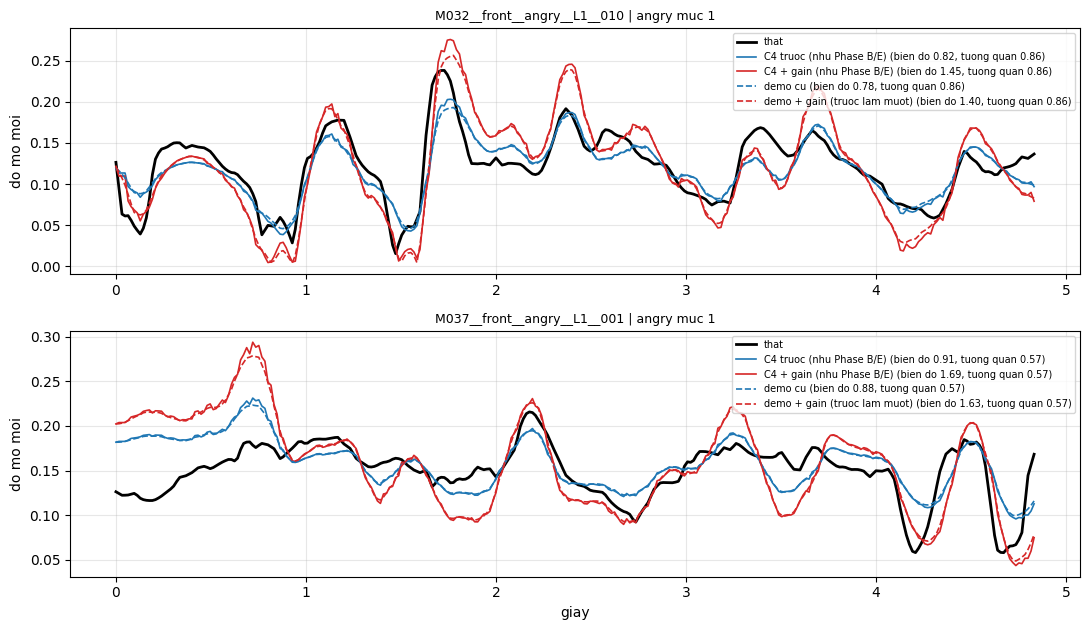

Da luu vao /content/drive/MyDrive/DAT301m/Data_student/student_a2l/phaseH:
   mouth_gain.json (28482 byte)
   phaseH_val_search.csv (26276 byte)
   phaseH_test_results.csv (13773 byte)
   phaseH_test_table.md (4160 byte)
   phaseH_mouth_open.png (239607 byte)

Dung trong demo / benchmark (Cell 1): MOUTH_GAIN_PATH = '/content/drive/MyDrive/DAT301m/Data_student/student_a2l/phaseH/mouth_gain.json'
  (tren Colab thuong la '/content/drive/MyDrive/DAT301m/Data_student/student_a2l/phaseH/mouth_gain.json')


In [10]:
GAIN_JSON = dict(
    phase='H', created=time.strftime('%Y-%m-%d %H:%M'),
    checkpoint=str(CKPT.relative_to(DRIVE)) if not _T else CKPT.name, pca_source=PCA_SRC,
    method=KIND, alpha=PAR if KIND == 'per_component' else None, scalar=PAR if KIND == 'scalar' else None,
    chosen=CHOSEN, gain=[float(v) for v in GAIN],
    order=ORDER,
    order_note={'before_smooth': 'nhan gain TRUOC lam muot: gain -> kep PCA -> lam muot 110 ms -> silence gate',
                'after_smooth': 'nhan gain SAU lam muot: kep PCA -> lam muot 110 ms -> gain -> silence gate'}[ORDER],
    g_k_raw=[float(v) for v in G_RAW], g_k_clipped=[float(v) for v in G_K], gain_range=list(GAIN_RANGE),
    selection=('VAL (%s), chuoi demo (kep %.1f sigma + muot %d ms): ung vien gain = g_k**alpha (alpha in %s) va he so chung '
               'in [%.2f, %.2f], moi gain thu nhan truoc / sau lam muot; giu ung vien co M-LMD mieng <= %.2f x demo cu va '
               'ti le rung (du doan/that) <= %.1f; chon bien do gan 1 nhat (bang nhau -> tuong quan cao hon)'
               % ('+'.join(SPLIT['val']), DEMO_MC['prior_clamp'], DEMO_MC['smooth_ms'], [a for a in ALPHAS if a > 0],
                  SCALARS[0], SCALARS[-1], 1 + MLMD_TOL, RUNG_MAX)),
    apply='M (T,136) da tru TB clip: Z = (M[:, idx] - mean) @ comps.T; M[:, idx] += (Z * (gain - 1)) @ comps; '
          'vi tri trong chuoi hau xu ly theo `order`',
    val=dict(base=VAL[BASE_NAME], chosen=VAL[CHOSEN], final=VAL_FINAL, final_ok=VAL_FINAL_OK),
    test={k: RES[k] for k in RES}, test_check=CHECK, n_boot=N_BOOT,
    idx=[int(v) for v in PIDX], mean=[float(v) for v in PMU], comps=PV.tolist(), pca_sigma=[float(v) for v in PSIG],
    clamp_changed=bool(CLAMP['changed']), prior_clamp=CLAMP['prior_clamp'], clamp_sigma=[float(v) for v in CLAMP['sigma']],
    clamp_sigma_source=CLAMP['sigma_src'], clamp_keep_old=CLAMP['keep_old'], clamp_keep_new=CLAMP['keep_new'],
    clamp_search=CLAMP['table'], keep_residual=DEMO_MC['keep_residual'],
    clamp_note=('Kep cu %.1f sigma giu lai %.0f%% phan khuech dai -> doi thanh %.1f x sigma du lieu that'
                % (DEMO_MC['prior_clamp'], 100 * CLAMP['keep_old'], CLAMP['prior_clamp']) if CLAMP['changed']
                else 'Giu nguyen kep %.1f sigma' % DEMO_MC['prior_clamp']),
    mouth_limits_note='Demo van giu gioi han mieng theo pixel: open_ratio 0.30, jaw_drop 0.12, max_width 1.20, jaw_side 0.05',
)
(OUT / 'mouth_gain.json').write_text(json.dumps(GAIN_JSON, indent=1, ensure_ascii=False))
(OUT / 'phaseH_test_table.md').write_text(MD)

import matplotlib
if not IN_COLAB:
    matplotlib.use('Agg')
import matplotlib.pyplot as plt
# 2 clip co cam xuc, khac speaker, dai nhat trong 4 s - 8 s (de nhin ro)
pick, seen = [], set()
for i in sorted(range(len(DTE['clips'])), key=lambda i: -min(DTE['clips'][i]['n'], 500)):
    c = DTE['clips'][i]
    if c['sp'] not in seen and (c['emo'] > 0 or len(DTE['clips']) < 20):
        pick.append(i); seen.add(c['sp'])
    if len(pick) == N_PLOT:
        break
CURVES = [('C4 truoc (nhu Phase B/E)', compose(T_ROWS[_raw0][0], DTE), 'C0-'),
          ('C4 + gain (nhu Phase B/E)', compose(T_ROWS['C4 + gain (Phase H)'][0], DTE), 'C3-'),
          ('demo cu', compose(T_ROWS[_dem0][0], DTE), 'C0--'),
          ('demo + gain (%s)' % ORDER_VN[ORDER], compose(T_ROWS[FINAL_DEMO][0], DTE), 'C3--')]
fig, axs = plt.subplots(len(pick), 1, figsize=(11, 3.2 * len(pick)), squeeze=False)
for ax, i in zip(axs[:, 0], pick):
    c = DTE['clips'][i]; a_, b_ = c['pos'], c['pos'] + c['n']; ref = DTE['refs'][c['sp']]; t_ = np.arange(c['n']) / 62.5
    og = mouth_open(DTE['raw'][a_:b_] + ref)
    ax.plot(t_, og, 'k-', lw=2, label='that')
    for lab, P_, sty in CURVES:
        y_ = mouth_open(P_[a_:b_] + ref)
        ax.plot(t_, y_, sty, lw=1.2, label='%s (bien do %.2f, tuong quan %.2f)' % (lab, y_.std() / (og.std() + 1e-12), corr(og, y_)))
    ax.set_title('%s | %s muc %d' % (c['name'], EMO_NAMES[c['emo']], c['lvl']), fontsize=9)
    ax.set_ylabel('do mo moi'); ax.legend(fontsize=7, loc='upper right'); ax.grid(alpha=.3)
axs[-1, 0].set_xlabel('giay')
fig.tight_layout(); fig.savefig(OUT / 'phaseH_mouth_open.png', dpi=120)
if IN_COLAB:
    plt.show()
plt.close(fig)
print('Da luu vao %s:' % OUT)
for f in ('mouth_gain.json', 'phaseH_val_search.csv', 'phaseH_test_results.csv', 'phaseH_test_table.md', 'phaseH_mouth_open.png'):
    print('  ', f, '(%d byte)' % (OUT / f).stat().st_size)
print('\nDung trong demo / benchmark (Cell 1): MOUTH_GAIN_PATH = %r' % str(OUT / 'mouth_gain.json'))
print("  (tren Colab thuong la '/content/drive/MyDrive/DAT301m/Data_student/student_a2l/phaseH/mouth_gain.json')")